## Objective: 

In this notebook, we will use an Energy Based model trained on the MNIST dataset to sample new images. 
We will guide the sampling process such that it produces samples for a particular class. The guidance will be provided 
by a classifier that is separately trained on the MNIST dataset. 

## Derivation

\begin{equation}
E(x, y) = E(x) - log p( y| x)
\end{equation}

In [16]:
import torch

In [30]:
class GuidedLangevinSampler:
    def __init__(self, energy_model, classifier_model):
        self.energy_model = energy_model
        self.classifier_model = classifier_model

    def generate_samples(self, x, y, num_steps=100, step_size=1.0):
        """
        Perform guided Langevin sampling using a classifier model to guide the sampling process.
        
        Args:
            x (torch.Tensor): Noise input tensor of shape (batch_size, channels, height, width)
            y (torch.Tensor): Target labels tensor of shape (batch_size,)
            num_steps (int): Number of Langevin sampling steps to perform
            step_size (float): Step size for the Langevin updates
        
        Returns:
            torch.Tensor: Updated sample tensor after one step of guided Langevin sampling.
        """
        # List for storing generations at each step (for later analysis)
        samples_per_step = []

        # Set the energy model and classifier model to evaluation mode
        self.energy_model.eval()
        self.classifier_model.eval()

        # Disable gradient computation for the energy model and classifier model parameters
        for param in self.energy_model.parameters():
            param.requires_grad = False
        for param in self.classifier_model.parameters():
            param.requires_grad = False

        # Perform Langevin sampling for the specified number of steps
        for step in range(num_steps):
            # Enable gradient computation for the input tensor
            x.requires_grad_(True)

            # Compute the energy of the current sample using the energy model
            energy = self.energy_model(x)  # [batch_size, 1]

            # Compute the log probability of the target class using the classifier model
            logits = self.classifier_model(x)  # [batch_size, num_classes]
            log_prob = torch.nn.functional.log_softmax(logits, dim=1)  # [batch_size, num_classes]
            target_log_prob = log_prob[:, y]  # [batch_size]

            # Combine the energy and log probability to get the overall score for the current sample
            combined_energy_score = torch.mean(energy.squeeze()) # -  target_log_prob)

            # Backpropagate to compute the gradient of the combined energy score with respect to the input
            combined_energy_score.backward()

            # Get the gradient of the combined energy score with respect to the input
            grad = x.grad.data  # [batch_size, channels, height, width]

            # Update the sample using the Langevin dynamics update rule
            sigma = 0.005  # Standard deviation for the noise
            noise = sigma * torch.randn_like(x)   # [batch_size, channels, height, width]

            # Go in the direction of the negative gradient to minimize the energy, and add noise for exploration
            x.data.add_(-step_size * grad + noise)  # [batch_size, channels, height, width]

            # Detach the gradient and zero it out for the next iteration
            # Also clamp the values of x to be within a reasonable range (e.g., [-1, 1]) to prevent divergence
            x.grad.detach_()
            x.grad.zero_()
            x.data.clamp_(min=-1.0, max=1.0)

            # Store the generated samples at this step for later analysis
            samples_per_step.append(x.detach().cpu())
        
        return x, samples_per_step

In [31]:
# Load the trained energy model and classifier model checkpoints
import torch
from cnn_energy import CNNEnergy
from cnn_classifier import CNNClassifier

energy_model = CNNEnergy()
classifier_model = CNNClassifier()

energy_model.load_state_dict(torch.load("cnn_energy_mnist_gen_ep_10.ckpt"))
classifier_model.load_state_dict(torch.load("cnn_classifier_ep_8.ckpt"))

<All keys matched successfully>

In [ ]:
# Create an instance of the GuidedLangevinSampler with the loaded models

sampler = GuidedLangevinSampler(energy_model, classifier_model)

# Example usage: Generate samples for a specific target class (e.g., digit '3')
batch_size = 1
num_classes = 10
target_class =2
noise = torch.randn(batch_size, 1, 28, 28)  # Random noise input

target_labels = torch.full((batch_size,), target_class, dtype=torch.long)

generated_samples, samples_per_step = sampler.generate_samples(noise, target_labels, num_steps=50, step_size=10.0)

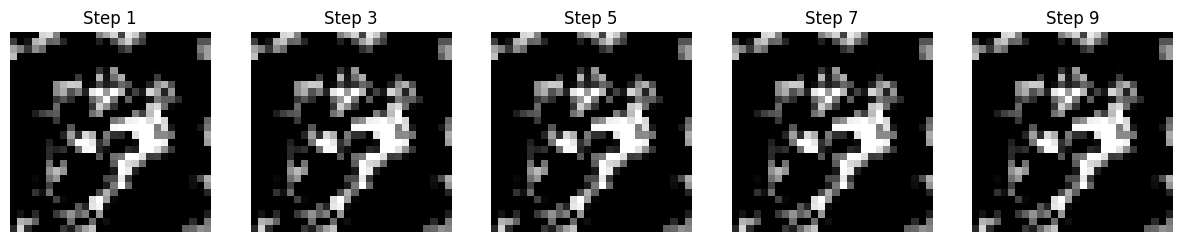

In [ ]:
# Visualize the generated samples at different steps of the Langevin sampling process
import matplotlib.pyplot as plt

num_steps_to_visualize = [10, 20, 30, 40, 49]  # Steps at which to visualize the samples
plt.figure(figsize=(15, 3))
for i, step in enumerate(num_steps_to_visualize):
    plt.subplot(1, len(num_steps_to_visualize), i + 1)
    plt.imshow(samples_per_step[step][0].squeeze(), cmap='gray')
    plt.title(f'Step {step}')
    plt.axis('off')
plt.show()